In [ ]:


import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import scipy.stats
import sklearn


import sklearn.pipeline
import sklearn.impute
import sklearn.linear_model
import sklearn.dummy
import sklearn.metrics


print("Python environment:", sys.executable)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("SciPy version:", scipy.__version__)
print("Scikit-learn version:", sklearn.__version__)

print("All libraries imported successfully!")


In [ ]:


df = pd.read_csv("energydata_clean.csv")


df["date"] = pd.to_datetime(df["date"])


if "hour" not in df.columns:
    df["hour"] = df["date"].dt.hour


if "day_night" not in df.columns:
    df["day_night"] = np.where(
        df["hour"].between(6, 21),
        "Day",
        "Night"
    )


display(df.head())


print("Dataset dimensions:", df.shape)


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,hour,day_night
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,17,Day
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,17,Day
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,17,Day
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,17,Day
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,17,Day


Dataset dimensions: (19735, 29)


Summary Statistics

Descriptive statistics were calculated to understand household appliance energy consumption. The Appliances column was selected because it represents household appliance energy usage.

The analysis includes count, mean, median, standard deviation, variance, minimum, maximum, range, quartiles, and interquartile range.

In [ ]:


appliances = df["Appliances"]


summary = pd.DataFrame({
    "Statistic": [
        "Count",
        "Mean",
        "Median",
        "Standard Deviation",
        "Variance",
        "Minimum",
        "Maximum",
        "Range",
        "Q1",
        "Q3",
        "IQR"
    ],

    "Value": [
        appliances.count(),
        np.mean(appliances),
        np.median(appliances),
        np.std(appliances, ddof=1),
        np.var(appliances, ddof=1),
        np.min(appliances),
        np.max(appliances),
        np.max(appliances) - np.min(appliances),
        np.percentile(appliances, 25),
        np.percentile(appliances, 75),
        np.percentile(appliances, 75) -
        np.percentile(appliances, 25)
    ]
})

display(summary.round(2))


,Statistic,Value
0,Count,19735.00
1,Mean,97.69
2,Median,60.00
3,Standard Deviation,102.52
4,Variance,10511.35
5,Minimum,10.00
6,Maximum,1080.00
7,Range,1070.00
8,Q1,50.00
9,Q3,100.00


Day vs Night Summary Statistics

The dataset was divided into daytime and nighttime observations to compare household appliance energy consumption.

The count, mean, median, and standard deviation were calculated for each period.

In [ ]:


day_night_summary = df.groupby("day_night")["Appliances"].agg(
    ["count", "mean", "median", "std"]
).round(1)

display(day_night_summary)


,count,mean,median,std
day_night,,,,
Day,13159,119.7,80.0,118.1
Night,6576,53.7,50.0,26.9


Interpretation

The results show that average appliance consumption during the Day was 119.7 Wh, compared with 53.7 Wh during the Night.

The difference between the two averages is 66.0 Wh.

The daytime median was 80 Wh, while the nighttime median was 50 Wh. This indicates that typical appliance consumption was also higher during daytime.

The standard deviation was higher during the Day (118.1 Wh) than during the Night (26.9 Wh), indicating greater variation in daytime consumption.

Overall, the descriptive statistics suggest that household appliance consumption was higher during daytime.

Data Cleaning Steps

The dataset was prepared during Step 2 before conducting the analysis.

The following cleaning procedures were performed:

1. Date conversion: The date column was converted into datetime format to support time-based analysis.

2. Missing-value checking: The dataset was checked for missing values to identify incomplete records.

3. Duplicate checking: Duplicate rows were examined to prevent repeated records from affecting the analysis.

4. Feature creation: An hour column was created from the date information to examine consumption patterns throughout the day.

5. Day and Night classification: A day_night column was created. Observations from 6:00 AM to 9:59 PM were classified as Day, while observations from 10:00 PM to 5:59 AM were classified as Night.

6. Removal of unnecessary columns: The rv1 and rv2 columns were removed because they were not required for the analysis.

7. Outlier examination: The IQR method was used to identify potential outliers. High consumption readings were retained because they were not confirmed to be errors.

After cleaning, the dataset contained 19,735 observations and 29 columns.

Statistical Test: Day vs Night Appliance Consumption

A paired-samples t-test was selected to determine whether daily average appliance consumption differs between daytime and nighttime.

Null Hypothesis (H0): There is no difference between the average daily Day and Night consumption.

Alternative Hypothesis (H1): There is a difference between the average daily Day and Night consumption.

The significance level is 0.05.

In [ ]:


daily_averages = (
    df.groupby([df["date"].dt.date, "day_night"])["Appliances"]
    .mean()
    .unstack()
)


daily_averages = daily_averages.dropna(
    subset=["Day", "Night"]
)

display(daily_averages.head(10))

print("Number of paired dates:", len(daily_averages))


day_night,Day,Night
date,,
2016-01-11,126.666667,161.666667
2016-01-12,93.020833,71.041667
2016-01-13,119.479167,52.083333
2016-01-14,205.937500,42.291667
2016-01-15,151.979167,72.083333
2016-01-16,156.875000,62.083333
2016-01-17,188.750000,50.625000
2016-01-18,118.854167,44.166667
2016-01-19,102.812500,44.166667


Number of paired dates: 138


Mean difference: 65.51023123331788
Median difference: 56.97916666666667
Standard deviation: 46.02587265795225


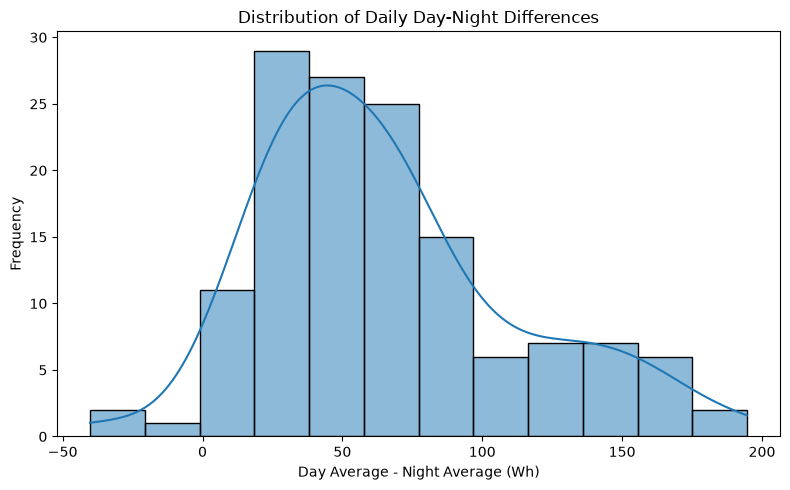

Shapiro-Wilk statistic: 0.9464670541324892
Shapiro-Wilk p-value: 3.626172557589812e-05


In [19]:


differences = (
    daily_averages["Day"] -
    daily_averages["Night"]
)


print("Mean difference:", np.mean(differences))
print("Median difference:", np.median(differences))
print("Standard deviation:", np.std(differences, ddof=1))


plt.figure(figsize=(8, 5))

sns.histplot(differences, kde=True)

plt.title("Distribution of Daily Day-Night Differences")
plt.xlabel("Day Average - Night Average (Wh)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


shapiro_stat, shapiro_p = scipy.stats.shapiro(differences)

print("Shapiro-Wilk statistic:", shapiro_stat)
print("Shapiro-Wilk p-value:", shapiro_p)


In [ ]:


t_statistic, p_value = scipy.stats.ttest_rel(
    daily_averages["Day"],
    daily_averages["Night"]
)

print("T-statistic:", t_statistic)
print("P-value:", p_value)


alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis.")
    print("There is a statistically significant difference.")
else:
    print("Fail to reject the null hypothesis.")
    print("There is insufficient evidence of a statistically significant difference.")


T-statistic: 16.720399277373527
P-value: 6.83083680264095e-35
Reject the null hypothesis.
There is a statistically significant difference.


In [ ]:


mean_difference = np.mean(differences)


n = len(differences)


standard_error = scipy.stats.sem(differences)


confidence_interval = scipy.stats.t.interval(
    confidence=0.95,
    df=n - 1,
    loc=mean_difference,
    scale=standard_error
)

print("Mean difference:", mean_difference)
print("95% Confidence Interval:", confidence_interval)


Mean difference: 65.51023123331788
95% Confidence Interval: (np.float64(57.762690411036914), np.float64(73.25777205559885))


In [ ]:


model_df = df.sort_values("date").copy()


model_df["target_next"] = (
    model_df["Appliances"].shift(-1)
)


model_df = model_df.dropna(subset=["target_next"])


features = [
    "Appliances", "lights",
    "T1", "RH_1", "T2", "RH_2",
    "T3", "RH_3", "T4", "RH_4",
    "T5", "RH_5", "T6", "RH_6",
    "T7", "RH_7", "T8", "RH_8",
    "T9", "RH_9",
    "T_out", "Press_mm_hg",
    "RH_out", "Windspeed",
    "Visibility", "Tdewpoint", "hour"
]


features = [
    column for column in features
    if column in model_df.columns
]


X = model_df[features].copy()


day_night_encoded = pd.get_dummies(
    model_df["day_night"],
    prefix="period",
    drop_first=True,
    dtype=int
)

X = pd.concat(
    [X, day_night_encoded],
    axis=1
)


y = model_df["target_next"]

print("Number of predictors:", X.shape[1])
print("Number of observations:", len(X))


Number of predictors: 28
Number of observations: 19734


In [ ]:


split_index = int(len(X) * 0.80)


X_train = X.iloc[:split_index]
y_train = y.iloc[:split_index]


X_test = X.iloc[split_index:]
y_test = y.iloc[split_index:]

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))


Training observations: 15787
Testing observations: 3947


In [ ]:


model = sklearn.pipeline.Pipeline([
    ("imputer", sklearn.impute.SimpleImputer(
        strategy="median"
    )),
    ("regression", sklearn.linear_model.LinearRegression())
])


model.fit(X_train, y_train)


predictions = model.predict(X_test)

print("Linear Regression model trained successfully!")


Linear Regression model trained successfully!


In [ ]:


baseline = sklearn.dummy.DummyRegressor(
    strategy="mean"
)


baseline.fit(X_train, y_train)


baseline_predictions = baseline.predict(X_test)

print("Baseline model trained successfully!")


Baseline model trained successfully!


In [ ]:


comparison = pd.DataFrame({
    "Metric": [
        "MAE",
        "RMSE",
        "R-squared"
    ],

    "Linear Regression": [
        sklearn.metrics.mean_absolute_error(
            y_test, predictions
        ),
        np.sqrt(
            sklearn.metrics.mean_squared_error(
                y_test, predictions
            )
        ),
        sklearn.metrics.r2_score(
            y_test, predictions
        )
    ],

    "Baseline": [
        sklearn.metrics.mean_absolute_error(
            y_test, baseline_predictions
        ),
        np.sqrt(
            sklearn.metrics.mean_squared_error(
                y_test, baseline_predictions
            )
        ),
        sklearn.metrics.r2_score(
            y_test, baseline_predictions
        )
    ]
})

display(comparison.round(3))


,Metric,Linear Regression,Baseline
0,MAE,27.824,52.686
1,RMSE,61.329,91.053
2,R-squared,0.546,-0.000


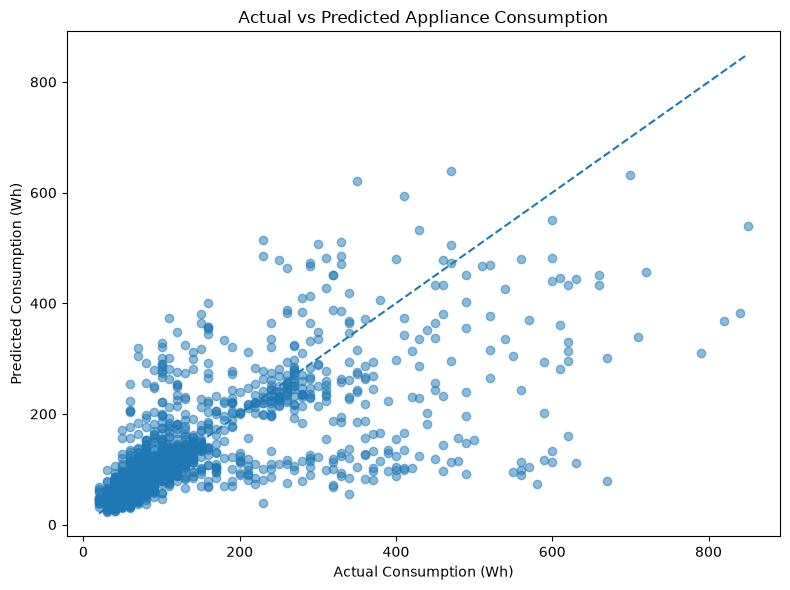

In [17]:

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    predictions,
    alpha=0.5
)

minimum = min(y_test.min(), predictions.min())
maximum = max(y_test.max(), predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.title("Actual vs Predicted Appliance Consumption")
plt.xlabel("Actual Consumption (Wh)")
plt.ylabel("Predicted Consumption (Wh)")

plt.tight_layout()
plt.show()


Relationship Between Two Variables

A scatter plot was created to examine the relationship between kitchen temperature (T1) and appliance energy consumption (Appliances).

The Pearson correlation coefficient was calculated to measure the strength and direction of their linear relationship.

Pearson correlation: 0.0554474718520363


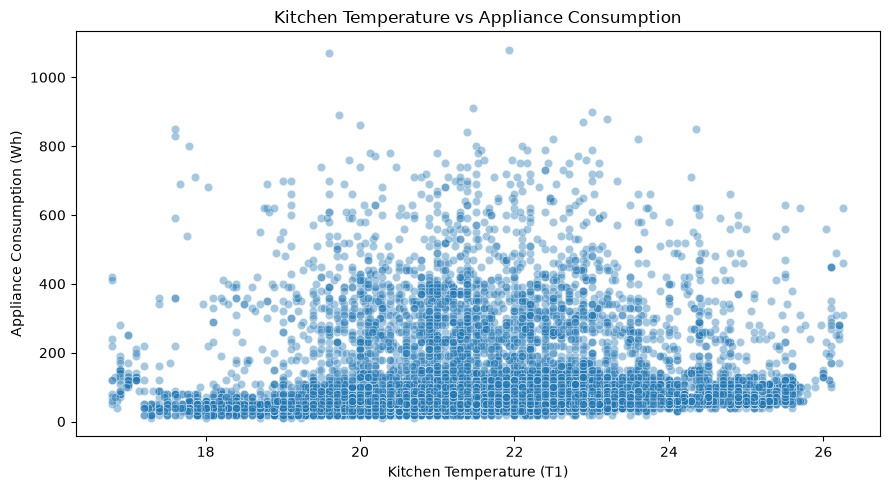

In [18]:

# Calculate Pearson correlation
correlation = df["T1"].corr(df["Appliances"])

print("Pearson correlation:", correlation)

# Create scatter plot
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="T1",
    y="Appliances",
    alpha=0.4
)

plt.title("Kitchen Temperature vs Appliance Consumption")
plt.xlabel("Kitchen Temperature (T1)")
plt.ylabel("Appliance Consumption (Wh)")

plt.tight_layout()
plt.show()



Correlation, Causation, Data Leakage, and Overfitting

1.Correlation versus Causation

Correlation describes an association between two variables. However, correlation does not prove causation.

For example, kitchen temperature may be associated with appliance energy consumption, but this does not prove that temperature directly causes changes in appliance consumption. Other factors, such as household activities and time of day, may also influence energy usage.

2.Data Leakage

Data leakage occurs when information that would not be available at prediction time is used in model training or evaluation.

To reduce this risk, the dataset was sorted chronologically and divided into training and testing datasets. The model uses current observations to predict the next recorded appliance consumption value.

The predictors must represent information genuinely available when the prediction is made.

3.Overfitting

Overfitting occurs when a model learns patterns specific to its training data but performs poorly on new observations.

To examine this risk, the Linear Regression model was evaluated on a separate chronological testing dataset and compared with a mean-based baseline model.

This comparison helps determine whether the model provides useful predictions beyond a simple average prediction.


Conclusion

The analysis examined household appliance energy consumption using descriptive statistics, statistical testing, data visualization, and machine learning.

The descriptive statistics provided information about the mean, median, spread, and number of appliance consumption observations.

The Day versus Night comparison showed that average appliance consumption was higher during daytime than nighttime in the recorded dataset.

A paired-samples t-test was conducted to investigate whether the difference between daily Day and Night averages was statistically significant. The normality of paired differences was examined, and a 95% confidence interval was calculated.

A scatter plot and Pearson correlation coefficient were used to examine the relationship between kitchen temperature and appliance energy consumption.

Finally, a Linear Regression model was developed using scikit-learn to predict the next recorded appliance consumption value. Its performance was compared with a mean-based baseline using MAE, RMSE, and R-squared.

Overall, the analysis provides insight into household energy consumption patterns and demonstrates the application of statistical analysis and machine learning.
